# AI Workforce Intelligence, Phase 4: Monte Carlo cost and value engine (CS3216 Time Series Analysis and Forecasting)

Phase 4 turns the Phase 3 forecast paths and a company's own inputs into monthly cost, value and a break-even range, with honest labels for what is forecast, estimated or assumed.

> **Where this fits.** This is **Phase 4** of 6.
> **Needs:** the Phase 3 forecast tables, `inputs_for_phase4.json` and the scenario table (inside the zip), plus company inputs (`config/example_company.json`, an illustrative example).
> **Produces:** `outputs/phase4/`: break-even and cost tables, figures, `assumptions.json`, used by the Phase 5 dashboard.

> **How to use this notebook**
> 1. In Colab: *Runtime > Run all*. When asked, upload `ai-workforce-intel_colab.zip` (the same zip for all three notebooks).
> 2. `MODE = "show"` (default) only displays the finished results inside the zip: under 1 minute.
> 3. `MODE = "run"` recomputes **this phase only** (under 1 minute (both --fast and full) on Colab), using the earlier phases' results in the zip.
> 4. Outside Colab, put the unzipped `ai-workforce-intel` folder (or the zip) next to this notebook.

In [1]:
# ---- Settings: change these, then Runtime > Run all ----
MODE = "show"       # "show": display the finished results in the bundle (under 1 minute)
                    # "run":  recompute Phase 4 first, then display the new results
RUN_FAST = True     # only for MODE = "run": True = --fast, False = full run
DRIVERS = None      # None = all drivers, or a list such as ["burst_tokens_total_daily"]
PHASE = 4

import os
MODE = os.environ.get("TSAF_MODE", MODE)  # used only by the automated test; ignore in Colab
print("Phase", PHASE, "| MODE =", MODE, "| RUN_FAST =", RUN_FAST, "| DRIVERS =", DRIVERS or "all")

Phase 4 | MODE = show | RUN_FAST = True | DRIVERS = all


### Helper functions
Small helpers used by every step: `step` turns any problem into a one-line message (so *Run all*
never stops), `show_img` and `show_table` display figures and tables at a readable size, and
`show_source` prints a real function from the project.

In [2]:
import contextlib, importlib, inspect, json, re, subprocess, sys, time, warnings
from pathlib import Path
import pandas as pd
from IPython.display import Image, Markdown, display

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 12)
pd.set_option("display.max_colwidth", 90)

@contextlib.contextmanager
def step(name):
    """Run one notebook step; a problem prints a short message instead of a traceback."""
    try:
        yield
    except FileNotFoundError as exc:
        print(f"[{name}] skipped: a result file is missing ({Path(str(exc.filename or exc)).name}).")
    except Exception as exc:
        print(f"[{name}] skipped: {type(exc).__name__}: {str(exc)[:200]}")

def show_img(path, width=900):
    """Display a saved PNG figure, or a short message if it does not exist."""
    path = Path(path)
    if not path.exists():
        print(f"No figure {path.name}; skipped.")
        return
    display(Image(filename=str(path), width=width))

def show_table(df, n=10, cols=None, digits=3):
    """Display the first n rows of a table, selected columns, rounded numbers."""
    if df is None or len(df) == 0:
        print("No rows to show.")
        return
    df = df[[c for c in cols if c in df.columns]] if cols else df
    display(df.head(n).round(digits).reset_index(drop=True))

def read_table(phase, name):
    """Read outputs/<phase>/tables/<name>.csv."""
    return pd.read_csv(Path("outputs") / phase / "tables" / f"{name}.csv")

def md_section(path, title):
    """Text of the '## ... title ...' section of a generated summary file (None if absent)."""
    text = Path(path).read_text(encoding="utf-8")
    pat = r"^## [^\n]*" + re.escape(title) + r"[^\n]*\n(.*?)(?=^## |\Z)"
    m = re.search(pat, text, flags=re.M | re.S)
    return m.group(1).strip() if m else None

def show_source(module, func, max_lines=25):
    """Print the source of module.func (first max_lines lines), or a short message."""
    try:
        obj = getattr(importlib.import_module(module), func)
        lines = inspect.getsource(obj).splitlines()
    except Exception as exc:
        print(f"Could not find {module}.{func}: {type(exc).__name__}; skipped.")
        return
    more = f"\n# ... {len(lines) - max_lines} more lines" if len(lines) > max_lines else ""
    display(Markdown(f"`{module}.{func}`\n```python\n" + "\n".join(lines[:max_lines]) + more + "\n```"))

## Setup 1: get the project
If the project folder is not here yet, the cell asks you to upload `ai-workforce-intel_colab.zip`
(about 10 MB), unzips it and moves into the folder. Outside Colab it looks for the folder (or the zip)
next to the notebook. The commented lines show how to unzip it from Google Drive instead.

In [3]:
def _is_project(p):
    return (p / "src" / "run_phase2.py").exists()

def _find_project():
    here = Path.cwd()
    for c in (here, here / "ai-workforce-intel", Path("/content/ai-workforce-intel")):
        if _is_project(c):
            return c
    return None

def _get_zip():
    if os.environ.get("TSAF_BUNDLE_PATH"):          # automated test: no upload dialog
        return Path(os.environ["TSAF_BUNDLE_PATH"])
    if Path("ai-workforce-intel_colab.zip").exists():
        return Path("ai-workforce-intel_colab.zip")
    try:
        from google.colab import files               # only exists inside Colab
    except ImportError:
        print("Not in Colab: place ai-workforce-intel_colab.zip or the unzipped folder next to this notebook.")
        return None
    print("Please upload ai-workforce-intel_colab.zip")
    uploaded = files.upload()
    return Path(next(iter(uploaded))) if uploaded else None

# Alternative: unzip from Google Drive instead of uploading (uncomment the two lines):
# from google.colab import drive; drive.mount("/content/drive")
# import zipfile; zipfile.ZipFile("/content/drive/MyDrive/ai-workforce-intel_colab.zip").extractall("/content")

PROJECT = None
with step("get the project"):
    PROJECT = _find_project()
    if PROJECT is None:
        zpath = _get_zip()
        if zpath is not None and zpath.exists():
            import zipfile
            base = Path("/content") if Path("/content").is_dir() else Path.cwd()
            zipfile.ZipFile(zpath).extractall(base)
            PROJECT = base / "ai-workforce-intel"
    if PROJECT is not None and _is_project(PROJECT):
        os.chdir(PROJECT)
        if str(PROJECT / "src") not in sys.path:
            sys.path.insert(0, str(PROJECT / "src"))
        print("Project ready: working folder is", Path.cwd().name)
    else:
        print("Project not found. Upload the zip and run this cell again.")

Project ready: working folder is ai-workforce-intel


## Setup 2: packages
Colab already has pandas, numpy, statsmodels, scikit-learn, matplotlib and pyarrow. This cell installs
only what is missing from `requirements.txt`, plus `xgboost` if it is missing. Prophet and torch are
optional and are never installed automatically.

In [4]:
IMPORT_NAME = {"scikit-learn": "sklearn"}
with step("packages"):
    wanted = []
    for line in Path("requirements.txt").read_text().splitlines():
        line = line.split("#")[0].strip()
        if line:
            wanted.append(re.split(r"[<>=!~ ]", line)[0])
    missing = []
    for pkg in wanted + ["xgboost"]:
        try:
            importlib.import_module(IMPORT_NAME.get(pkg, pkg))
        except ImportError:
            missing.append(pkg)
    if missing:
        print("Installing:", ", ".join(missing))
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--disable-pip-version-check", *missing], check=False)
    else:
        print("All required packages are already installed.")
    import numpy, statsmodels, sklearn, matplotlib
    print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | numpy {numpy.__version__} | "
          f"statsmodels {statsmodels.__version__} | scikit-learn {sklearn.__version__} | matplotlib {matplotlib.__version__}")
    import optional
    for name, ok in [("xgboost", optional.has_xgboost()), ("prophet", optional.has_prophet()), ("torch (LSTM)", optional.has_torch())]:
        print(f"  optional {name:13s}: {'available' if ok else 'not installed (model skipped)'}")

All required packages are already installed.
Python 3.11.9 | pandas 3.0.5 | numpy 2.4.6 | statsmodels 0.15.0 | scikit-learn 1.9.0 | matplotlib 3.11.1


  optional xgboost      : available
  optional prophet      : not installed (model skipped)
  optional torch (LSTM) : available


## Setup 3: seeds and project layout
All randomness uses seed 42, so a rerun gives the same numbers.

In [5]:
with step("seeds and tree"):
    import random, numpy as np
    random.seed(42)
    np.random.seed(42)
    for top in sorted(p for p in Path(".").iterdir() if p.is_dir() and not p.name.startswith(".")):
        subs = sorted(q.name for q in top.iterdir() if q.is_dir() and q.name != "__pycache__")
        print(f"{top.name}/" + (f"  ->  {', '.join(subs)}" if subs else ""))

config/
data/  ->  processed
outputs/  ->  phase1, phase2, phase3, phase4
reports/  ->  figures
src/  ->  engine, tsaf
tests/


## Run (only when `MODE = "run"`)
In `show` mode nothing is recomputed. In `run` mode this cell runs `python src/run_phase4.py` exactly as in a
terminal (this phase only; earlier phases' results come from the zip), then the notebook shows the new results.

In [6]:
def run_script(args):
    """Run one project script and print the last lines of its log."""
    t0 = time.time()
    res = subprocess.run([sys.executable, *args], capture_output=True, text=True)
    for line in (res.stdout + res.stderr).strip().splitlines()[-8:]:
        print("   ", line[:150])
    print(f"  -> exit code {res.returncode}, {time.time() - t0:.0f} s")
    return res.returncode

with step("run"):
    if MODE == "run":
        extra = ["--drivers", *DRIVERS] if DRIVERS else []
        fast = ["--fast"] if RUN_FAST else []
        print("Estimated time on Colab's CPU: under 1 minute (both --fast and full).")
        T0 = time.time()
        run_script(["src/run_phase4.py", *fast, *extra])
        print(f"Total elapsed: {(time.time() - T0) / 60:.1f} minutes")
    else:
        print("MODE = 'show': displaying the finished results in outputs/ (nothing is recomputed).")

MODE = 'show': displaying the finished results in outputs/ (nothing is recomputed).


## 1. The question
**What will an AI programme cost, what does it return, and when does it break even?** The engine combines the
Phase 3 forecast paths (wages, hosting prices, token demand) with a company's own numbers (people, training,
engineering hours) and a time-saved scenario, and runs thousands of possible futures.

In [7]:
ENGINE = {}
with step("load the engine"):
    import logging
    logging.getLogger("engine").setLevel(logging.ERROR)  # the fallback is reported below in plain words
    import config, config_phase4 as P4
    from engine.inputs import load_inputs
    from engine.drivers import load_drivers
    from engine.simulate import run_engine, summarise
    INPUTS, RAW = load_inputs(P4.EXAMPLE_INPUTS)
    SC_TABLE = pd.read_csv(P4.PHASE3_DIR / "forecasts" / "scenario_tables.csv")
    DRIVERS_T = load_drivers(int(INPUTS["horizon_months"]), P4.PHASE3_DIR, config.DATA_DIR)
    ENGINE.update(inputs=INPUTS, drivers=DRIVERS_T, scenarios=SC_TABLE)
    print("Engine ready: horizon", INPUTS["horizon_months"], "months;", len(DRIVERS_T.drivers), "drivers loaded")
    for role, d in DRIVERS_T.drivers.items():
        if d.used_fallback:
            print(f"Note: {role} uses a fallback: {d.note}")

Engine ready: horizon 12 months; 4 drivers loaded
Note: token_price uses a fallback: no Epoch price forecast: flat fixed_token_price_per_mtok from the inputs (an estimate)


## 2. The four outputs and their labels
Every cost or value line says what kind of evidence it rests on. *Forecast-driven* lines move with the Phase 3
forecasts; *estimates* come from the company's own inputs; *projections* rest on scenario assumptions.
The labels matter because a reader must not mistake an assumption for a forecast.

In [8]:
with step("labels"):
    rows = [{"output": P4.LINE_LABEL[k], "type": P4.LINE_TYPE[k]} for k in P4.LINE_LABEL]
    show_table(pd.DataFrame(rows))

,output,type
0,Token expenditure,Forecast-driven
1,Infrastructure / hosting,Forecast-driven
2,Workforce enablement,Estimate
3,Integration,Estimate
4,Business outcomes (value),Projection


## 3. The example company
**Every value below is illustrative**: an invented example company used to demonstrate the engine. Replace
them with real numbers (edit `config/example_company.json` or pass `--inputs your_file.json`).

In [9]:
with step("inputs"):
    a = json.loads(Path("outputs/phase4/assumptions.json").read_text(encoding="utf-8"))
    t = pd.DataFrame([{"input": k, "value": v["value"], "unit": v["unit"], "type": v["evidence_type"],
                       "note": v["note"]} for k, v in a["inputs"].items()])
    show_table(t, n=30)

,input,value,unit,type,note
0,employees,500,people,illustrative,people in scope of the AI programme
1,adoption_start,0.05,share,illustrative,pilot group already using AI in month 1
2,adoption_target,0.6,share,illustrative,share of employees using AI at the end of the ramp
3,ramp_months,6,months,illustrative,months to reach the adoption target
4,ramp_shape,linear,,illustrative,linear or logistic adoption curve
5,tokens_per_active_user_per_month,17600,tokens,illustrative,"from WildChat consumer chats (about 4,060 output tokens per active user per week x 52/..."
6,price_multiplier_vs_frontier,1.0,x,illustrative,only used with an Epoch price forecast (not available yet)
7,fixed_token_price_per_mtok,5.0,USD per million tokens,illustrative,flat blended price used because there is no Epoch price forecast; replace with your co...
8,base_monthly_hosting_cost,2000.0,USD per month,illustrative,infrastructure cost today; moves with the PPI hosting forecast
9,base_hourly_wage_staff,45.0,USD per hour,illustrative,fully loaded staff wage today; moves with the ECI wage forecast


## 4. From forecast paths to monthly numbers
Each Phase 3 path becomes a month-by-month series. Hosting costs follow the PPI hosting index, wages the ECI
wage index (interpolated from quarters to months). Beyond a driver's forecast horizon the last forecast value is
carried forward **flat**, and the engine counts how much cost falls in those extrapolated months.

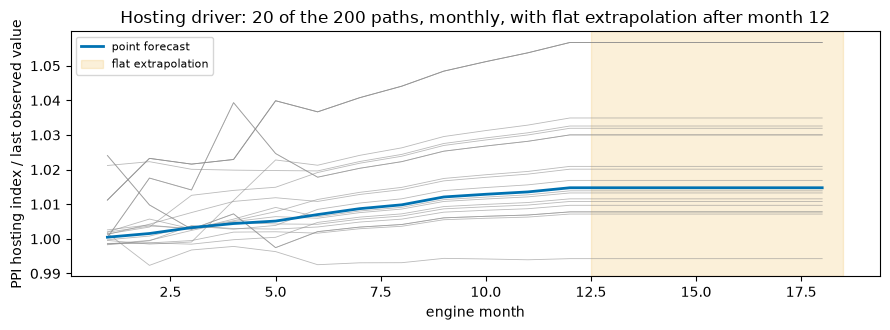

,role,driver,months_covered_by_forecast,months_extrapolated,share_of_total_cost_in_extrapolated_months,used_fallback
0,token_demand,burst_tokens_total_daily,1.0,11.0,0.001,False
1,wages,eci_wages_quarterly,12.0,0.0,0.000,False
2,hosting,ppi_hosting_monthly,12.0,0.0,0.000,False
3,token_price,fixed_token_price_per_mtok,12.0,0.0,0.000,True
4,any,any extrapolated driver,NaN,NaN,0.001,False


In [10]:
with step("path diagram"):
    import matplotlib.pyplot as plt
    long = load_drivers(18, P4.PHASE3_DIR, config.DATA_DIR)["hosting"]
    m = range(1, 19)
    fig, ax = plt.subplots(figsize=(9, 3.4))
    for row in long.paths[:20]:
        ax.plot(m, row, color="#8C8C8C", lw=0.6, alpha=0.6)
    ax.plot(m, long.point, color="#0072B2", lw=2, label="point forecast")
    ax.axvspan(long.covered_months + 0.5, 18.5, color="#E69F00", alpha=0.15, label="flat extrapolation")
    ax.set(xlabel="engine month", ylabel="PPI hosting index / last observed value",
           title="Hosting driver: 20 of the 200 paths, monthly, with flat extrapolation after month 12")
    ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()
    show_table(read_table("phase4", "extrapolation"), n=10)

## 5. One draw, step by step
One possible future for the expected scenario: the adoption ramp gives the active and new users, which drive
tokens, training and the value of saved time; each line is shown so the arithmetic can be followed.

time saved: 2.08449% of work hours / 100 = 0.02084


,month,active users,new users,ramped users (value),tokens (M),token cost,hosting,enablement,integration,value,net,cumulative net
0,1,71.0,46.0,8.0,1.0,0.0,1993.0,20613.0,20058.0,627.0,-42037.0,-42037.0
1,2,117.0,46.0,32.0,2.0,0.0,1996.0,21355.0,20115.0,2411.0,-41056.0,-83093.0
2,3,162.0,46.0,71.0,3.0,1.0,1987.0,22101.0,20173.0,5361.0,-38900.0,-121993.0
3,4,208.0,46.0,117.0,4.0,1.0,2031.0,22835.0,1213.0,8848.0,-17231.0,-139224.0
4,5,254.0,46.0,162.0,4.0,1.0,2033.0,23571.0,1215.0,12349.0,-14470.0,-153695.0
5,6,300.0,46.0,208.0,5.0,1.0,2029.0,24310.0,1218.0,15864.0,-11693.0,-165388.0
6,7,300.0,0.0,254.0,5.0,1.0,2033.0,7580.0,1221.0,19414.0,8578.0,-156810.0
7,8,300.0,0.0,285.0,5.0,1.0,2037.0,7594.0,1225.0,21814.0,10957.0,-145853.0
8,9,300.0,0.0,300.0,5.0,1.0,2042.0,7608.0,1229.0,23054.0,12174.0,-133679.0
9,10,300.0,0.0,300.0,5.0,1.0,2045.0,7616.0,1231.0,23091.0,12199.0,-121481.0


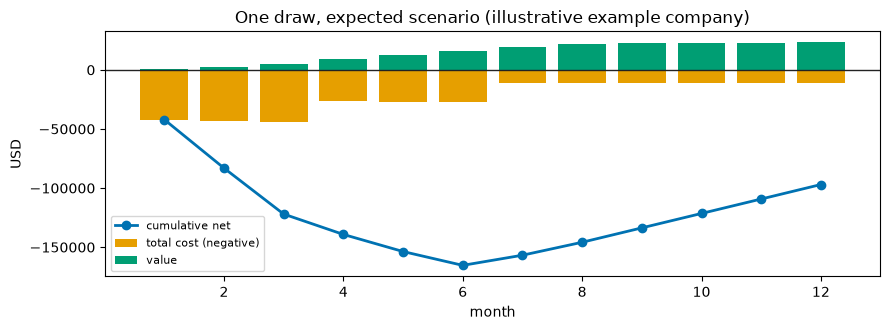

In [11]:
with step("one draw"):
    r = run_engine(INPUTS, "expected", 1.0, 1, 42, DRIVERS_T, SC_TABLE)
    T = r.meta["T"]
    one = pd.DataFrame({"month": range(1, T + 1), "active users": r.meta["U"], "new users": r.meta["N"],
                        "ramped users (value)": r.meta["E"],
                        "tokens (M)": r.meta["U"] * INPUTS["tokens_per_active_user_per_month"] / 1e6,
                        "token cost": r.lines["token_expenditure"][0], "hosting": r.lines["hosting"][0],
                        "enablement": r.lines["enablement"][0], "integration": r.lines["integration"][0],
                        "value": r.value[0], "net": r.net[0], "cumulative net": r.cum_net[0]})
    print(f"time saved: {r.meta['scenario_info']['conversion']}")
    show_table(one, n=T, digits=0)
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(figsize=(9, 3.4))
    ax.bar(one["month"], -one[["token cost", "hosting", "enablement", "integration"]].sum(axis=1),
           color="#E69F00", label="total cost (negative)")
    ax.bar(one["month"], one["value"], color="#009E73", label="value")
    ax.plot(one["month"], one["cumulative net"], color="#0072B2", lw=2, marker="o", label="cumulative net")
    ax.axhline(0, color="#222222", lw=1)
    ax.set(xlabel="month", ylabel="USD", title="One draw, expected scenario (illustrative example company)")
    ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()

## 6. Running 5,000 futures
Each draw picks one Phase 3 path per driver at random (independently between drivers) and computes every month.
The table gives, per scenario and uncertainty multiplier k, the probability of breaking even within the horizon
and the P10, P50 and P90 break-even month among the draws that do. The fan charts show the cumulative net.

,scenario,multiplier,prob_break_even_within_T,p10_month,p50_month,p90_month,share_no_break_even
0,downside,1.0,0.0,NaN,NaN,NaN,1.0
1,downside,1.5,0.0,NaN,NaN,NaN,1.0
2,downside,2.0,0.0,NaN,NaN,NaN,1.0
3,expected,1.0,0.0,NaN,NaN,NaN,1.0
4,expected,1.5,0.0,NaN,NaN,NaN,1.0
5,expected,2.0,0.0,NaN,NaN,NaN,1.0
6,optimistic,1.0,1.0,11.0,11.0,11.0,0.0
7,optimistic,1.5,1.0,11.0,11.0,11.0,0.0
8,optimistic,2.0,1.0,11.0,11.0,11.0,0.0


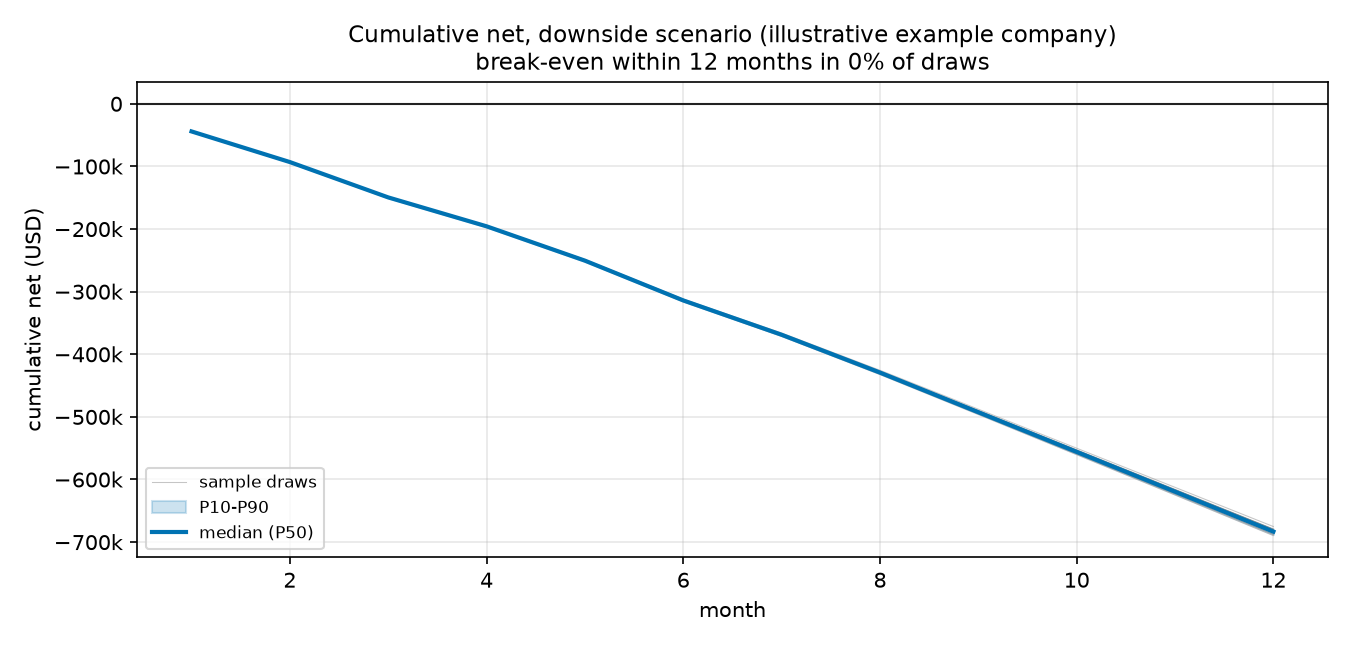

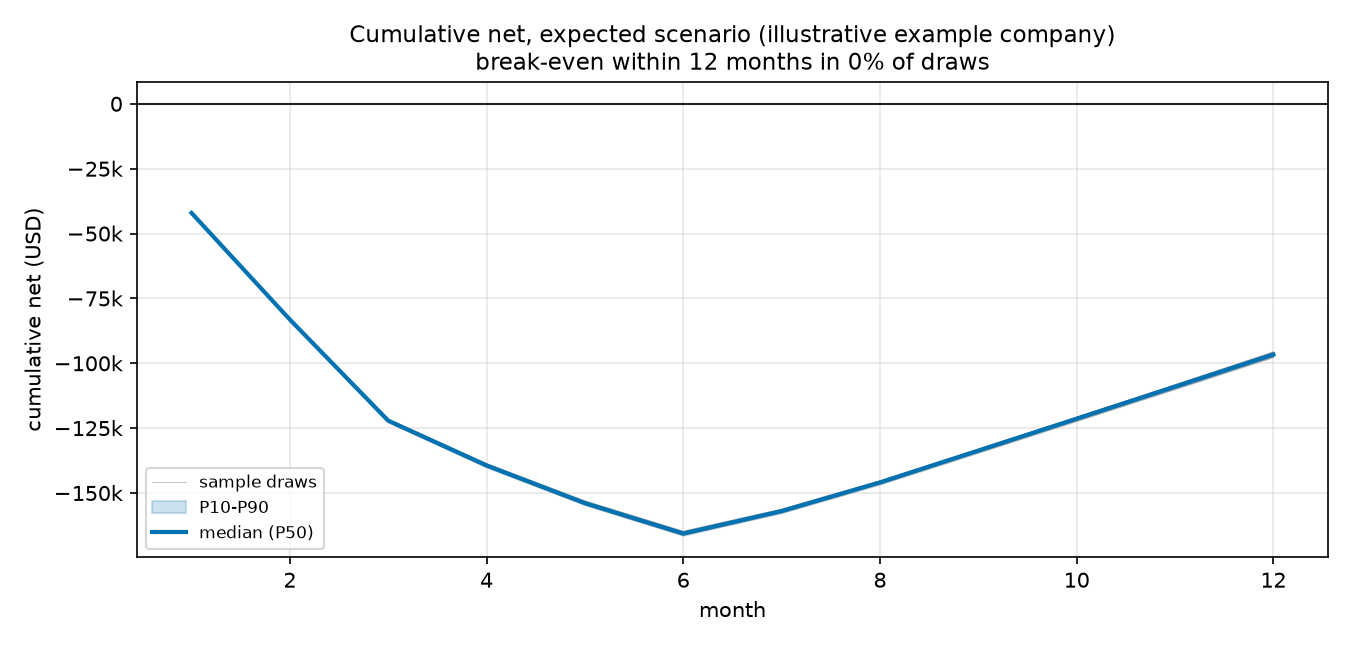

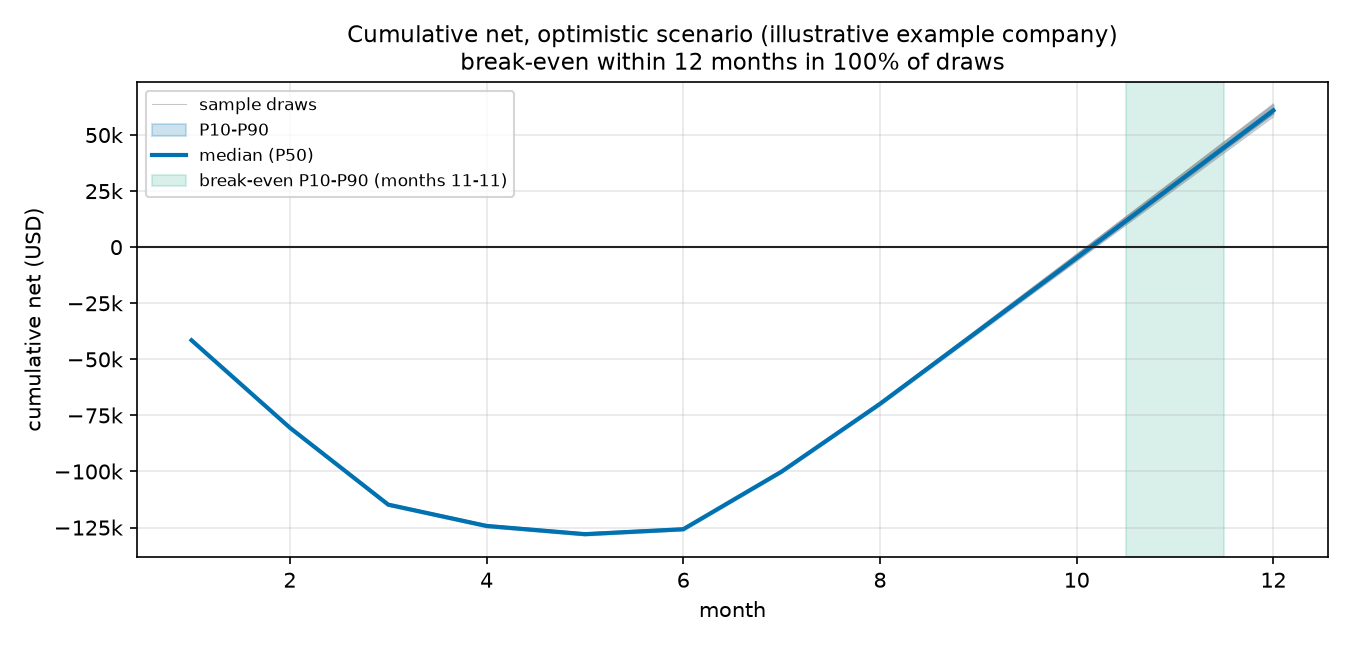

In [12]:
with step("break-even"):
    be = read_table("phase4", "break_even_summary")
    show_table(be, n=12, cols=["scenario", "multiplier", "prob_break_even_within_T", "p10_month", "p50_month",
                               "p90_month", "share_no_break_even"])
    for sc in ("downside", "expected", "optimistic"):
        show_img(f"outputs/phase4/figures/cumulative_net_{sc}.png", width=800)

## 7. Cost breakdown
Which line costs most, and how much of the cost rests on forecasts versus the company's own estimates.

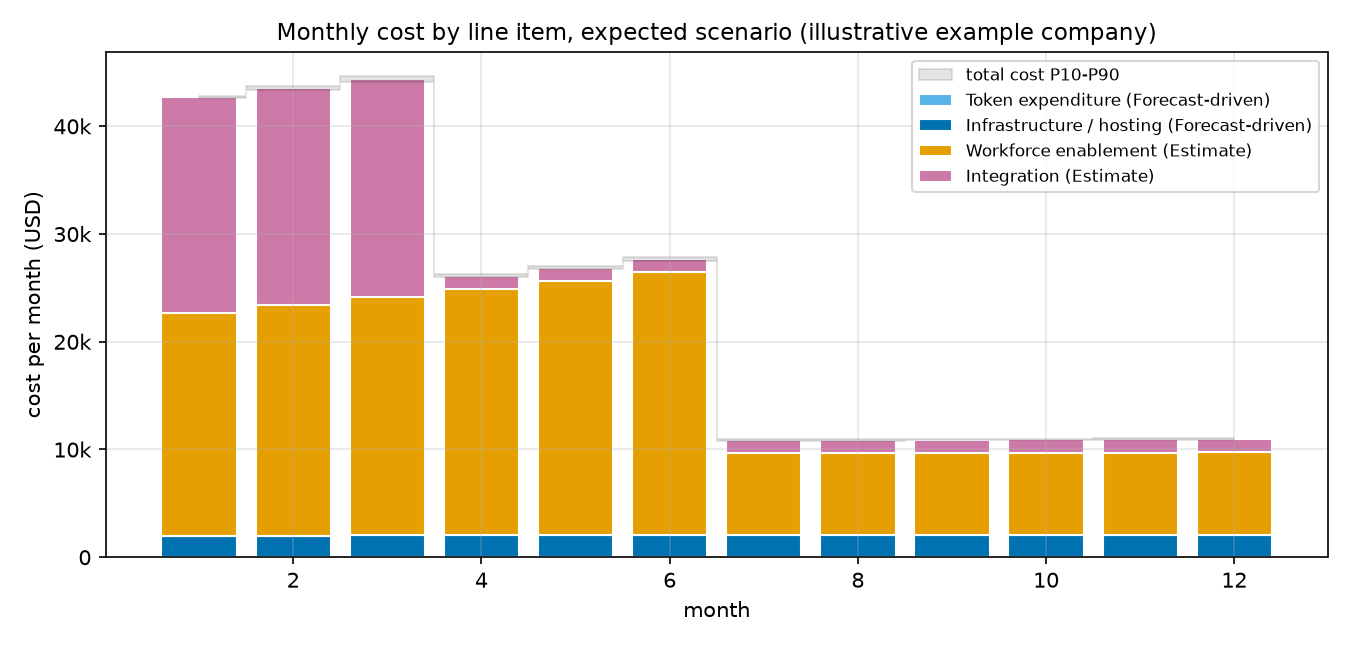

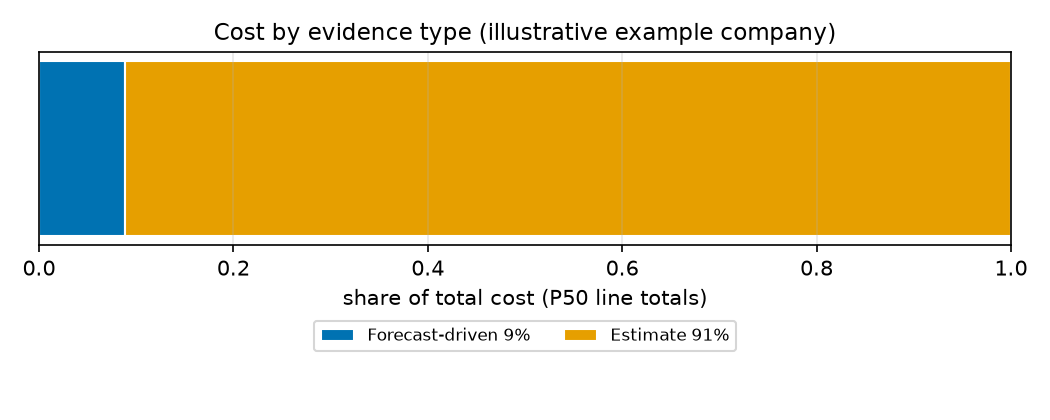


The largest line is **enablement** (65% of cost, Estimate). Forecast-driven lines are 9% of cost and estimated lines 91%, so most of the cost rests on the company's own inputs, not on the forecasts.

In [13]:
with step("breakdown"):
    show_img("outputs/phase4/figures/cost_stack_expected.png", width=800)
    show_img("outputs/phase4/figures/cost_share_by_type.png", width=600)
    text = md_section("outputs/phase4/PHASE4_SUMMARY.md", "Cost breakdown")
    if text:
        display(Markdown("\n".join(l for l in text.splitlines() if not l.startswith("|"))))

## 8. Scenarios and the uncertainty multiplier
The scenario chart compares downside, expected and optimistic time saved. The multiplier chart widens the forecast
uncertainty by k = 1.5 and 2.0 (Phase 3 found its intervals too narrow) and shows what changes.

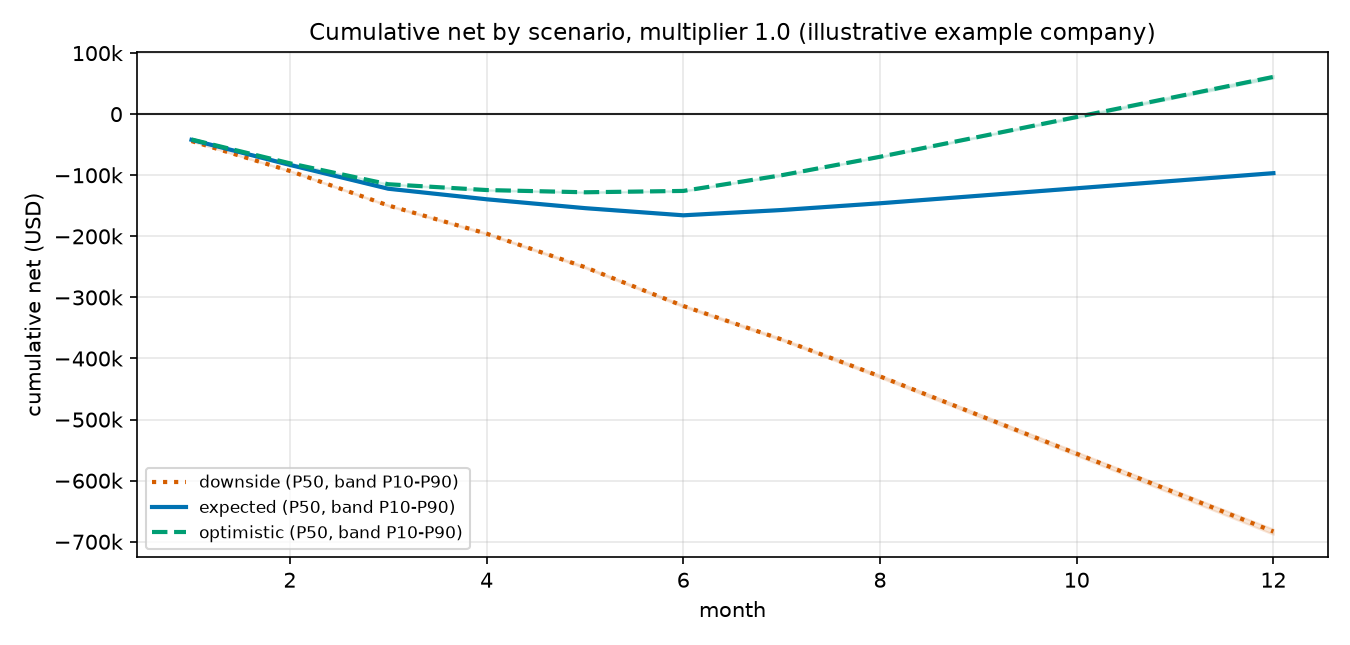

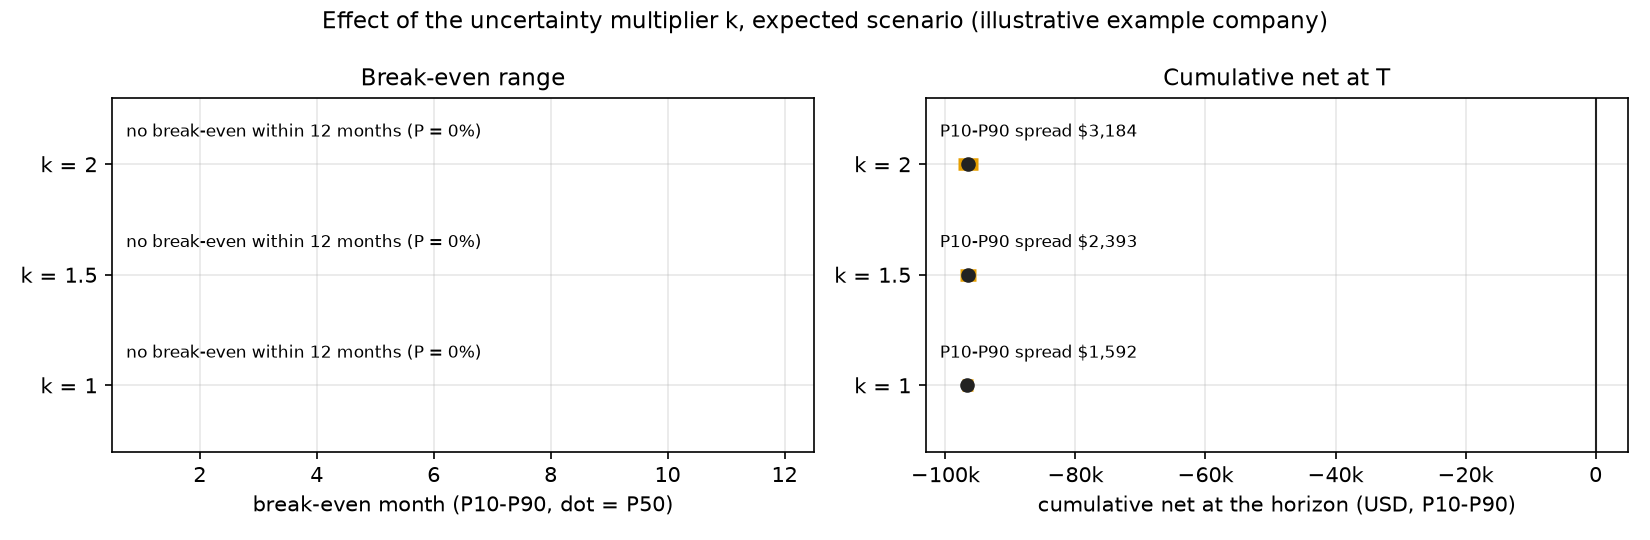

| scenario | k | P(break-even) | month P10/P50/P90 | total cost P50 | total value P50 | peak investment P50 | cum. net at T P50 |
|---|---|---|---|---|---|---|---|
| downside | 1 | 0% | none / none / none | $276,899 | $-406,466 | $683,306 | $-683,306 |
| downside | 1.5 | 0% | none / none / none | $277,301 | $-407,461 | $684,666 | $-684,666 |
| downside | 2 | 0% | none / none / none | $277,717 | $-408,456 | $686,029 | $-686,029 |
| expected | 1 | 0% | none / none / none | $276,899 | $180,271 | $165,662 | $-96,641 |
| expected | 1.5 | 0% | none / none / none | $277,301 | $180,712 | $165,816 | $-96,602 |
| expected | 2 | 0% | none / none / none | $277,717 | $181,153 | $165,970 | $-96,565 |
| optimistic | 1 | 100% | 11 / 11 / 11 | $276,899 | $337,956 | $127,968 | $60,928 |
| optimistic | 1.5 | 100% | 11 / 11 / 11 | $277,301 | $338,783 | $128,068 | $61,297 |
| optimistic | 2 | 100% | 11 / 11 / 11 | $277,717 | $339,610 | $128,168 | $61,660 |

Break-even months are counted among the draws that break even within 12 months; 'none' means no draw broke even within 12 months.

In [14]:
with step("compare"):
    show_img("outputs/phase4/figures/scenario_compare.png", width=800)
    show_img("outputs/phase4/figures/multiplier_effect.png", width=850)
    text = md_section("outputs/phase4/PHASE4_SUMMARY.md", "uncertainty multiplier")
    if text:
        display(Markdown(text))

## 9. Which inputs matter
Each main input is moved by -20% and +20% (an illustrative stress range, not a measured uncertainty) and the change
in median cumulative net at the horizon is shown. Long bars mark the inputs worth measuring carefully.

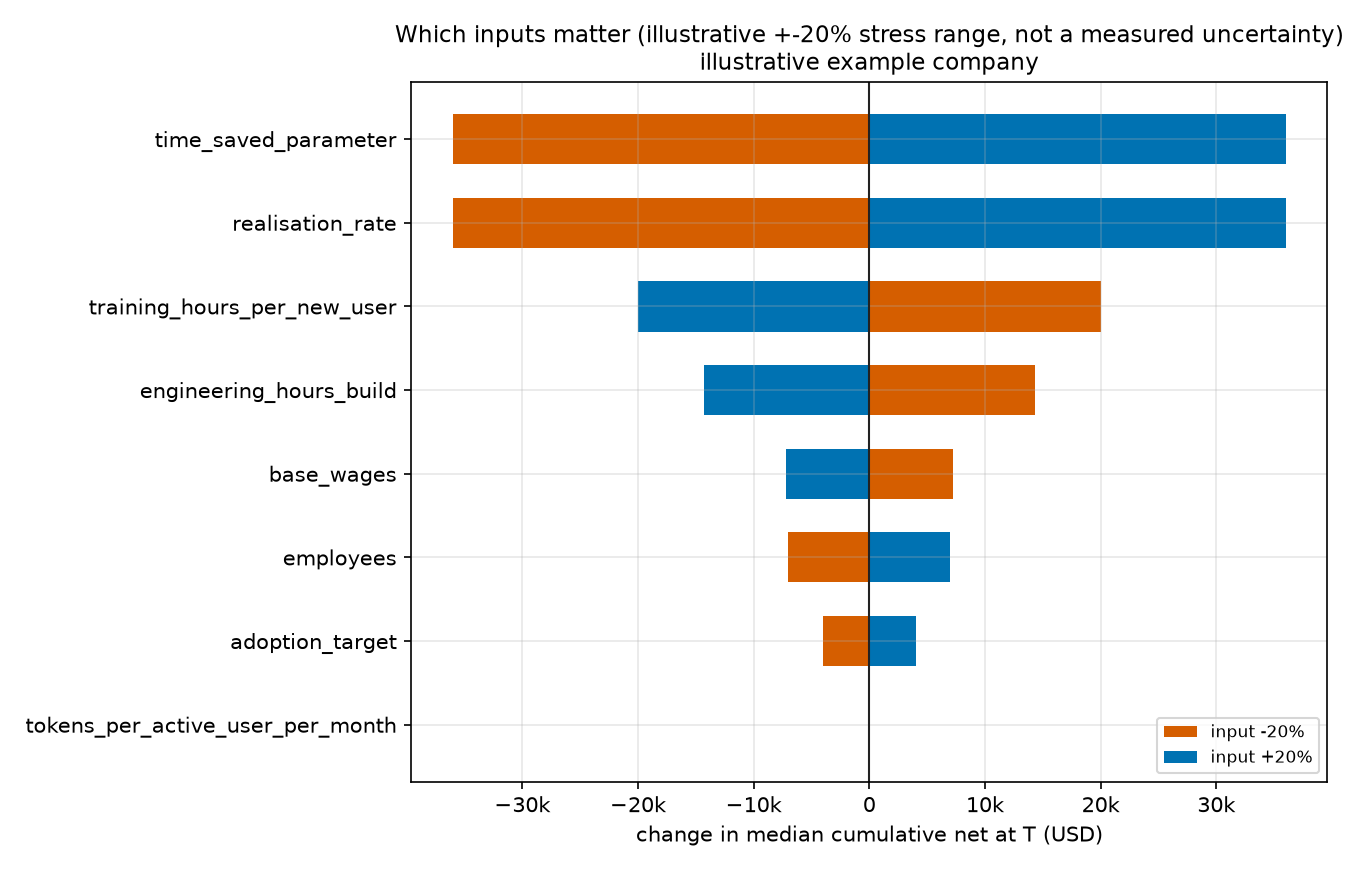

In [15]:
with step("tornado"):
    show_img("outputs/phase4/figures/tornado.png", width=750)

## 10. Try your own numbers (interactive, optional)
Move the sliders and press the button: the engine reruns with 2,000 draws and redraws the cumulative net.
Nothing else in the notebook depends on this cell.

In [16]:
with step("try your own numbers"):
    try:
        import ipywidgets as widgets
    except ImportError:
        widgets = None
        print("ipywidgets is not available; edit config/example_company.json and use MODE = 'run' instead.")
    if widgets is not None and ENGINE:
        import matplotlib.pyplot as plt
        import numpy as np
        w = {"employees": widgets.IntSlider(value=INPUTS["employees"], min=10, max=5000, step=10, description="employees"),
             "adoption_target": widgets.FloatSlider(value=INPUTS["adoption_target"], min=0.0, max=1.0, step=0.05, description="adoption"),
             "training_hours_per_new_user": widgets.FloatSlider(value=INPUTS["training_hours_per_new_user"], min=0, max=40, step=1, description="training h"),
             "engineering_hours_build": widgets.FloatSlider(value=INPUTS["engineering_hours_build"], min=0, max=5000, step=50, description="eng. hours"),
             "realisation_rate": widgets.FloatSlider(value=INPUTS["realisation_rate"], min=0.0, max=1.0, step=0.05, description="realisation")}
        scen = widgets.Dropdown(options=["expected", "optimistic", "downside"], value="expected", description="scenario")
        mult = widgets.Dropdown(options=[1.0, 1.5, 2.0], value=1.0, description="k")
        out = widgets.Output()
        def _redraw(_=None):
            out.clear_output()
            with out:
                inp = dict(INPUTS, **{k: v.value for k, v in w.items()})
                inp["adoption_target"] = max(inp["adoption_target"], inp["adoption_start"])
                res = run_engine(inp, scen.value, mult.value, 2000, 42, DRIVERS_T, SC_TABLE)
                s = summarise(res)["break_even"]
                p10, p50, p90 = np.percentile(res.cum_net, [10, 50, 90], axis=0)
                m = np.arange(1, res.cum_net.shape[1] + 1)
                fig, ax = plt.subplots(figsize=(8, 3.2))
                ax.fill_between(m, p10, p90, color="#0072B2", alpha=0.2, label="P10-P90")
                ax.plot(m, p50, color="#0072B2", lw=2, label="median")
                ax.axhline(0, color="#222222", lw=1)
                ax.set(xlabel="month", ylabel="cumulative net (USD)", title="Your inputs (illustrative)")
                ax.legend(fontsize=8)
                plt.show()
                print(f"P(break-even within {res.meta['T']} months) = {s['prob_within_T']:.0%}")
        btn = widgets.Button(description="Run 2,000 draws")
        btn.on_click(_redraw)
        display(widgets.VBox([*w.values(), scen, mult, btn]), out)
        _redraw()

Output()

## 11. Look at the code
Break-even is the first month whose cumulative net is at or above zero; the value of saved time ramps up for each
adoption cohort, computed for all months at once with a convolution.

In [17]:
with step("code"):
    show_source("engine.model", "break_even")
    show_source("engine.model", "effective_users")

`engine.model.break_even`
```python
def break_even(cum_net: np.ndarray) -> np.ndarray:
    """First month (1-based) with cumulative net >= 0, per draw; NaN if none within T."""
    hit = cum_net >= 0
    first = np.argmax(hit, axis=1).astype(float) + 1.0
    first[~hit.any(axis=1)] = np.nan
    return first
```

`engine.model.effective_users`
```python
def effective_users(U0: float, N: np.ndarray, lag: int) -> np.ndarray:
    """Users weighted by their benefit ramp, months 1..T (cohort convolution)."""
    T = len(N)
    cohorts = np.r_[U0, N]                       # adopted in month 0 (pilot) and months 1..T
    full = np.convolve(cohorts, benefit_ramp(lag, T))[: T + 1]
    return full[1:]
```

# Summary

The talking points and limitations below are taken directly from `PHASE4_SUMMARY.md`,
so every number comes from the run.

In [18]:
with step("summary"):
    for title in ("What to say in the review", "Limitations"):
        text = md_section("outputs/phase4/PHASE4_SUMMARY.md", title)
        display(Markdown(f"### Phase 4: {title}\n\n" + (text or "_Section not found._")))

### Phase 4: What to say in the review

The engine turns the Phase 3 forecast paths and a company's own inputs into monthly cost, value and break-even over 12 months, with 5,000 Monte Carlo draws per run. All company numbers here belong to an illustrative example company and must be replaced with real ones. In the expected scenario the programme does not break even within 12 months; median total cost $276,899 against median value $180,271. In the optimistic scenario the programme breaks even within 12 months in 100% of draws (median month 11); median total cost $276,899 against median value $337,956. In the downside scenario the programme does not break even within 12 months; median total cost $276,899 against median value $-406,466. The largest cost line is enablement (65%), an estimate; forecast-driven lines are 9% of cost. The tornado shows time_saved_parameter and realisation_rate move the result most. No public data links AI use to a company's outcomes, so value is a scenario projection, not a forecast. Uncertainty from the forecasts is widened by k = 1.5 and 2.0 because Phase 3 found its intervals too narrow.

### Phase 4: Limitations

- Drivers are drawn independently; their correlations are unknown.
- Months beyond a driver's forecast horizon are extrapolated flat (section 7).
- BurstGPT is one provider's trace; only its relative variation is used as a demand factor.
- Tokens per active user comes from WildChat consumer chats and counts output tokens only; it is not an enterprise measurement.
- The time-saved scenarios come from survey (FRED GenAI tracker) and trial (METR) evidence; the downside applies METR's task-time increase to the illustrative share of AI-assisted hours.
- Phase 3 found the forecast intervals under-cover on the holdout; the multipliers 1.5 and 2.0 are a sensitivity response, not a calibration.
- Engine month 1 is the first forecast month of each driver; the drivers' data end at different dates.
- The example company's inputs are illustrative. The measured input-token share is 86%.

In [19]:
with step("what we have"):
    display(Markdown("### What we have so far"))
    display(pd.DataFrame([{"phase": "1. exploration and baselines", "built": "loaders, decomposition, trend methods, ADF/KPSS, ACF/PACF, anomaly screen, 5 baselines, backtest", "outputs": "outputs/phase1: tables, figures, handoff.json, PHASE1_SUMMARY.md", "notebook": "TSAF_Phase1.ipynb"}, {"phase": "2. forecasting models and rolling backtests", "built": "smoothing, ARIMA/SARIMA/SARIMAX, Ridge/RF/XGBoost, ensemble, intervals, diagnostics, model choice", "outputs": "outputs/phase2: tables, figures, chosen_models.json, cv_residuals.parquet, PHASE2_SUMMARY.md", "notebook": "TSAF_Phase2.ipynb"}, {"phase": "3. simulated paths and the standard forecast table", "built": "refit of the chosen models, 200 bootstrap paths per driver, holdout interval check, standard table, scenarios", "outputs": "outputs/phase3: forecasts/*.parquet and .csv, manifest.json, inputs_for_phase4.json, PHASE3_SUMMARY.md", "notebook": "TSAF_Phase3.ipynb"}, {"phase": "4. Monte Carlo cost and value engine", "built": "cost lines (tokens, hosting, enablement, integration), value projection, break-even, multiplier, tornado", "outputs": "outputs/phase4: tables (break-even, totals, monthly), figures, assumptions.json, PHASE4_SUMMARY.md", "notebook": "TSAF_Phase4.ipynb"}]))

### What we have so far

,phase,built,outputs,notebook
0,1. exploration and baselines,"loaders, decomposition, trend methods, ADF/KPSS, ACF/PACF, anomaly screen, 5 baselines...","outputs/phase1: tables, figures, handoff.json, PHASE1_SUMMARY.md",TSAF_Phase1.ipynb
1,2. forecasting models and rolling backtests,"smoothing, ARIMA/SARIMA/SARIMAX, Ridge/RF/XGBoost, ensemble, intervals, diagnostics, m...","outputs/phase2: tables, figures, chosen_models.json, cv_residuals.parquet, PHASE2_SUMM...",TSAF_Phase2.ipynb
2,3. simulated paths and the standard forecast table,"refit of the chosen models, 200 bootstrap paths per driver, holdout interval check, st...","outputs/phase3: forecasts/*.parquet and .csv, manifest.json, inputs_for_phase4.json, P...",TSAF_Phase3.ipynb
3,4. Monte Carlo cost and value engine,"cost lines (tokens, hosting, enablement, integration), value projection, break-even, m...","outputs/phase4: tables (break-even, totals, monthly), figures, assumptions.json, PHASE...",TSAF_Phase4.ipynb


**Next: Phase 5, the dashboard**, will put `engine.simulate.run_engine` behind sliders so a company can enter its own numbers, using the same preloaded forecast paths. Then Phase 6, the report.